# Quantum Metal circuit examples A–E — every single-component and sub-circuit example on one test chip (Quantcore PDK rebuild)

**What the chip is.** Not a chip in the source: the 19 Qiskit Metal circuit-example notebooks
`docs/circuit-examples/{A.Qubits, B.Resonators, C.Composite-bi-partite, D.Qubit-couplers, E.Input-output-coupling}/*.ipynb`
(© IBM / Qiskit Metal contributors, Apache-2.0, <https://github.com/qiskit-community/qiskit-metal>; spec
`docs/designs/metal/component_examples.md`) each draw one component or a small sub-circuit. Here they are gathered on
one **catalogue board** as component tests for the `metal:` wrappers and their LOM models: each example on its own
7 × 7 mm tile of a 35 × 28 mm chip, with its Metal origin at the tile centre (instance names get the tile prefix, e.g.
`D31_Q1`). We distribute the rebuild under GPL-3.0.

**This notebook rebuilds them with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): every
Metal component is drawn through the `metal:<Class>` wrapper with the options its notebook set; the board, the stack,
the junctions, the routes, the netlist and the LOM are ours.

| | Qiskit Metal examples | Quantcore PDK rebuild |
|---|---|---|
| chip | one `DesignPlanar` per notebook, centred on (0, 0) | one 35 × 28 mm board of 7 × 7 mm tiles (it does not fit the 7.5 mm die), with the QCT die frame |
| substrate | silicon 750 µm, εr 11.45 (Metal default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| launchpads | E.41 / E.42 drive their own qubit / meander | kept **inside their tiles**: the pad rule is not applied to this catalogue board (Design 2); the two `pad_edge` design warnings stay |
| junctions | Metal junction lines (10 nH assumed) | Quantcore trilayer junctions: PDK nominal, PDK SQUIDs on the flux-tunable cells, the interdigitated transmon sized for 4.05 GHz; the A.08 / A.09 junction tiles keep Metal's own drawing (2/0 only, a reference) |
| cheese | none (no example exports GDS) | the PDK band (chip `cheese: "auto"`) |
| routes | `RouteMeander` / `RouteStraight` | qcc `cpw` routes on Metal's corner points (fixed-length meanders where needed), 10 / 6 µm |
| placement | each example at its origin | the tile grid centred in the die |

**Reproduced exactly:** the source-examples cell (after Setup) runs each example notebook's own code in a headless Metal design (GUI calls become
no-ops; analysis / render / export lines are skipped) and reads back the final design: every component with its
options as the notebook set them (the differences from Metal's template are passed to `metal:<Class>`), its position
and orientation, and every route's end pins, Metal corner points, fillet and length. `RouteMeander`s run on Metal's
corner points (into an `OpenToGround`: a plain CPW on that path; between two pads: a fixed-length meander, Metal's
length + 0.05 µm, which keeps the router on Metal's path); `RouteStraight` is a straight qcc CPW.

**Not reproduced:** the analysis cells (Q3D / HFSS / LOM / EPR in some notebooks need Ansys) and screenshots. The two
junction notebooks (A.08 `jj_dolan`, A.09 `jj_manhattan`) draw a junction on its own, with no pins and no circuit
element. B.11's meander runs between two `OpenToGround`s (a λ/2 on its own).

**How this notebook goes.** First the source examples are read (a headless Metal run of each notebook). Then the **Design**:
the board is laid out one example group at a time, each group its own cell with a picture of its tiles — the board
and its tile grid, a note on the pads, then **A** (the qubits), **B** (the resonator), **C** (the composite), **D**
(the qubit couplers), **E** (the input–output examples), and then the whole board. This is a catalogue board, not a
chip, so its segments are the example groups rather than pads → readout → qubits → coupling. Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in one cell, with its outputs) is kept as `component_examples.v1.ipynb`; both save the same
`component_examples.json`.

## Setup

The imports, the output folder and the switches. `LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it;
with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement, FEM and feedback helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots
import contextlib, glob, io, json, logging, re, warnings
from quantcore_circuits.circuit.bridges import size_junction
from quantcore_circuits.layouts.metal.geometry import template_options, PLACEMENT_OPTIONS
SRC = upstream_path("qiskit-metal", "docs/circuit-examples").as_posix() + "/"  # third_party/ or other-libs/

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The source examples

The cell below runs each of the 19 example notebooks in a headless Metal design and
reads back every component (class, position, orientation, the options that differ from Metal's template) and every
route (end pins, corner points, fillet, length). It prints one line per tile. (About half a minute.)

In [4]:
# run every example notebook's code in a headless Metal design and read back its final design
os.environ["QISKIT_METAL_HEADLESS"] = "True"
logging.disable(logging.CRITICAL); warnings.simplefilter("ignore")
import qiskit_metal
from qiskit_metal import Dict, designs
SKIP = re.compile(r"screenshot|savefig|display\(|Image\(|Analysis\(|\.sim\.|renderers|export_to|run_lom|run_epr|"
                  r"plot|qm\.view|metal\.view|\.close\(\)|pip install|^%|^!|get_convergence|setup\.|\.run\(")


class NoGui:                                     # stands in for MetalGUI: every call is a no-op
    def __getattr__(self, name): return NoGui()
    def __call__(self, *a, **k): return NoGui()


def plain(v):
    if isinstance(v, dict): return {k: plain(x) for k, x in v.items()}
    if isinstance(v, (list, tuple)): return [plain(x) for x in v]
    return float(v) if hasattr(v, "dtype") else v


EX = {}
for path in sorted(glob.glob(SRC + "[A-E].*/*.ipynb")):
    group, stem = Path(path).parent.name[0], Path(path).stem  # (Windows glob returns "\\" separators)
    tile = group + stem[:2]                      # e.g. A01, B11, D31
    g = {"NoGui": NoGui, "metal": qiskit_metal, "qm": qiskit_metal, "designs": designs, "Dict": Dict}
    for cell in json.load(open(path, encoding="utf-8"))["cells"]:
        if cell["cell_type"] != "code":
            continue
        src = "\n".join(l for l in "".join(cell["source"]).splitlines() if not SKIP.search(l.strip()))
        src = re.sub(r"(MetalGUI|metal\.gui|qm\.gui)\(design\)", "NoGui()", src)
        src = src.replace(", MetalGUI", "").replace("MetalGUI, ", "")
        try:
            with contextlib.redirect_stdout(io.StringIO()):
                exec(src, g)
        except Exception:                        # e.g. an optional GUI import; the design is read below
            pass
    design = g["design"]
    design.rebuild()
    comps, routes = {}, {}
    for name, c in design.components.items():
        cls, p = type(c).__name__, c.parse_options()
        if "pin_inputs" in c.options:            # a Metal route
            pi = c.options.pin_inputs
            routes[name] = dict(cls=cls, ends=(pi.start_pin.component, pi.start_pin.pin, pi.end_pin.component,
                                                pi.end_pin.pin),
                                pts=[(1000 * float(x), 1000 * float(y)) for x, y in c.get_points()],
                                fillet=1000 * float(p.fillet))
            routes[name]["length"] = (1000 * float(p.total_length) if cls == "RouteMeander" else  # straight: as drawn
                                      sum(math.dist(a, b) for a, b in zip(routes[name]["pts"], routes[name]["pts"][1:])))
        else:
            tmpl = template_options(cls)
            comps[name] = dict(cls=cls, at=(1000 * float(p.pos_x), 1000 * float(p.pos_y)), rot=float(p.orientation),
                               pins=list(c.pins),
                               opts={k: plain(v) for k, v in c.options.items()
                                     if k not in PLACEMENT_OPTIONS and k != "chip" and plain(v) != tmpl.get(k)})
    EX[tile] = dict(title=stem[3:].replace("_", " "), comps=comps, routes=routes)
logging.disable(logging.NOTSET)
for tile, ex in EX.items():
    print(tile, ex["title"], "|", ", ".join(f"{n} ({c['cls']})" for n, c in ex["comps"].items()),
          "|", ", ".join(f"{n} ({r['cls']}, {r['length']:.0f} µm)" for n, r in ex["routes"].items()))

A01 Transmon cross | Q1 (TransmonCross) | 
A02 Transmon floating | Q1 (TransmonPocket) | 
A03 concentric transmon | qubit1 (TransmonConcentric) | 
A04 Interdigitated Transmon | qubit1 (TransmonInterdigitated) | 
A05 Transmon cross fl | Q1 (TransmonCrossFL) | 
A06 Transmon floating 6 | Q1 (TransmonPocket6) | 
A07 Transmon floating cl | Q1 (TransmonPocketCL) | 
A08 JJ-Dolan | JJ2 (jj_dolan) | 
A09 JJ-Manhattan | JJ2 (jj_manhattan) | 
A10 Transmon floating teeth | Q1 (TransmonPocketTeeth) | 
A11 Star shaped qubit | Star (StarQubit) | 
B11 Resonator Meander | Open_meander_start (OpenToGround), Open_meander_end (OpenToGround) | meanderTest (RouteMeander, 9000 µm)
C21 OneTransmonsWithMeanderAndOTG | Q1 (TransmonPocket), open_to_ground (OpenToGround) | coupler (RouteMeander, 5000 µm)
D31 TwoCrossmonsTunableCoupler | Q1 (TransmonCrossFL), Q2 (TransmonCrossFL), Tune_C_Q12 (TunableCoupler01) | 
D32 TwoTransmonsDirectCoupling | Q1 (TransmonPocket), Q2 (TransmonPocket) | coupler (RouteStraight, 15

## The Quantcore PDK this board uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this board that means: the 35 × 28 mm box gets the QCT frame; every qubit gets a trilayer junction (nominal, a SQUID on the flux-tunable cells, sized for the interdigitated transmon); the free ground gets the PDK cheese band; the launchpads of the E tiles stay in their tiles (Design 2).

In [5]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the board, one example group at a time

The 19 examples go on their tiles group by group, in the source's order (the tiles fill the 5 × 4 grid left to right,
top to bottom): each segment places one group's components with their PDK junctions and then the group's routes, and
shows a picture of its tiles (live, KLayout redraws after every cell). The groups never share a component or a route,
so the order is the source's and the saved JSON is the same as a one-cell build.

| segment | what is placed here |
|---|---|
| 1 | the 35 × 28 mm board with the QCT frame, and the tile grid `CENTRE` |
| 2 | bond pads: none moved (why the pad rule is not applied to this catalogue board) |
| 3 | **A**, qubits: A.01–A.11 (crosses, pockets, concentric, interdigitated, star; the two junction tiles) |
| 4 | **B**, resonators: B.11, a λ/2 meander between two open ends |
| 5 | **C**, composite: C.21, a pocket qubit with its open meander |
| 6 | **D**, qubit couplers: D.31 (tunable coupler), D.32 (direct line), D.33 (λ/2 bus) |
| 7 | **E**, input–output: E.41–E.43 (coupled launchpads, a driven meander, a charge-line pocket) |
| 8 | the whole board: sim groups, centring, save |

## Design 1 · The board, its frame and the tile grid

`Designer(name, box=...)` opens an empty chip; the box is the die (µm) and the PDK draws the **QCT frame** on it (L
dicing markers 1000/0, 3 × 3 alignment grids 1001/0, chip boundary 100/0, device ID `name_chip` on a free edge). The
board is a 5 × 4 grid of 7 mm tiles, filled left to right and top to bottom in the examples' order (A01 … A11, B11,
C21, D31 … D33, E41 … E43); `CENTRE[tile]` is each tile's centre, where its Metal origin goes.

{'A01': (3500.0, 24500.0), 'A02': (10500.0, 24500.0), 'A03': (17500.0, 24500.0), 'A04': (24500.0, 24500.0), 'A05': (31500.0, 24500.0), 'A06': (3500.0, 17500.0), 'A07': (10500.0, 17500.0), 'A08': (17500.0, 17500.0), 'A09': (24500.0, 17500.0), 'A10': (31500.0, 17500.0), 'A11': (3500.0, 10500.0), 'B11': (10500.0, 10500.0), 'C21': (17500.0, 10500.0), 'D31': (24500.0, 10500.0), 'D32': (31500.0, 10500.0), 'D33': (3500.0, 3500.0), 'E41': (10500.0, 3500.0), 'E42': (17500.0, 3500.0), 'E43': (24500.0, 3500.0)}


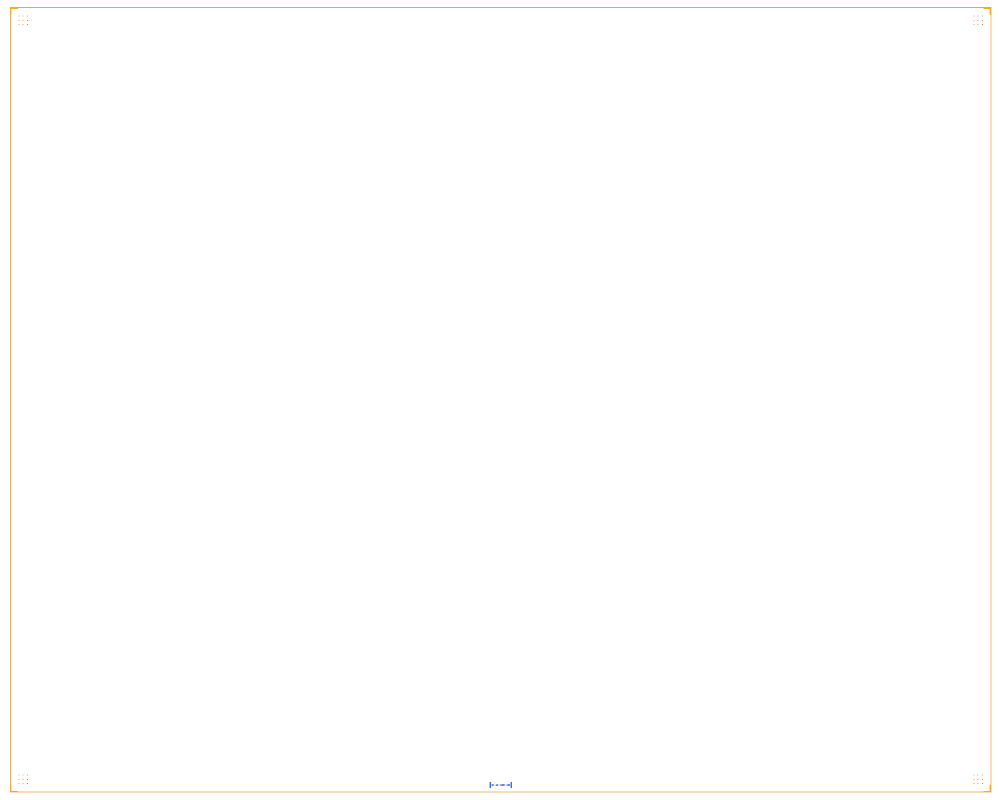

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/component_examples_s1_board.png')

In [6]:
PITCH, NCOL, NROW = 7000, 5, 4
d = Designer("component_examples", box=(0, 0, NCOL * PITCH, NROW * PITCH), chip={"name_chip": "MetalExamples"},
             live=LIVE)
CENTRE = {tile: ((k % NCOL + 0.5) * PITCH, (NROW - k // NCOL - 0.5) * PITCH) for k, tile in enumerate(EX)}
print({t: c for t, c in CENTRE.items()})


def tiles_box(group, half=3500):
    """The bounding box (µm) of the tiles of one example group ("A" … "E")."""
    xs = [CENTRE[t][0] for t in EX if t[0] == group]
    ys = [CENTRE[t][1] for t in EX if t[0] == group]
    return (min(xs) - half, min(ys) - half, max(xs) + half, max(ys) + half)


def group_view(group, png):
    """The segment's picture: the board so far, zoomed on the group's tiles (``layout_step``)."""
    x0, y0, x1, y1 = tiles_box(group)
    w = 1000 if x1 - x0 >= y1 - y0 else round(1000 * (x1 - x0) / (y1 - y0))
    return layout_step(d, png, box=(x0, y0, x1, y1), size=(w, round(w * (y1 - y0) / (x1 - x0))), width=max(240, w // 2))


layout_step(d, OUT / "component_examples_s1_board.png", size=(1000, 800), width=400)

## Design 2 · Bond pads: why the pad rule is not applied here

The PDK puts the outer etch of every bond pad **100 µm from the die edge** (`frame.pad_edge`). This board is a catalogue of component
examples, not a chip with I/O: its only launchpads are the two `LaunchpadWirebond`s of tiles **E.41** and **E.42**,
which drive the tile's own qubit (E.41) or open meander (E.42) over a few hundred µm. Sliding them to the board edge
(≈ 6 mm away, through other tiles) would break the examples they belong to, so they stay where their notebooks put
them, and the DRC keeps its two `pad_edge` design warnings for them (flagged, as the PDK asks, not enforced). They are
placed with their tiles in Design 7 (group E).

In [7]:
LAUNCHPADS = [(t, n, c["cls"], c["at"]) for t, ex in EX.items() for n, c in ex["comps"].items()
              if c["cls"].startswith("Launchpad")]
print("launchpads in the examples (tile, name, class, Metal position µm):", LAUNCHPADS)

launchpads in the examples (tile, name, class, Metal position µm): [('E41', 'P4_Q', 'LaunchpadWirebondCoupled', (990.0, 2812.0000000000005)), ('E42', 'P4_Q', 'LaunchpadWirebondCoupled', (990.0, 2812.0000000000005))]


## Design 3 · Group A: the qubits

Each tile gets its example's components at their Metal positions (plus the tile centre), with the notebook's options
(the differences from Metal's template). **Junctions:** every qubit class gets a Quantcore trilayer junction (`trilayer_junction`): the PDK nominal one (0.5 ×
0.6 µm fingers → R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF); the flux-tunable cells (`TransmonCrossFL`, `TunableCoupler01`)
a PDK SQUID (two 0.25 × 0.6 µm junctions, 45 kΩ in parallel); the interdigitated transmon (C_Σ ≈ 216 fF without the
junction, this design's LOM before the rebuild) is **sized for 4.05 GHz** (L_J ≈ 6.4 nH, R_n ≈ 43 kΩ) to stay in
the 4–8 GHz band (nominal: ≈ 3.95 GHz). `junction=` carries L_J / C_J to the LOM.

**Free pins:** Metal draws a pin with no route as an open end, so each component's unrouted pins are passed as
`open_pins` (the wrapper then draws them open, as Metal does).

**Claws vs arms (PDK `pdk_claw`):** a `TransmonCross` claw longer than the arm reach (arm + ground spacing − half the
arm width = 195 µm with Metal's 200 µm default arm) runs into the side arms' gap; the fix is a longer
`cross_length`. Here: 30 µm claws (A.01, A.05) and D.31's 95 µm bus claws, all inside the reach (zoom in Fab 2).

`place_tiles(group)` and `route_tiles(group)` do this for one group; the next segments call them for B … E.
**Routes:** Each example's routes on Metal's own corner points (`nodes`), 10 / 6 µm CPW, with Metal's fillet as the turn radius:
- a `RouteMeander` into an `OpenToGround`: a plain CPW on Metal's exact path (the LOM sees it as drawn);
- a `RouteMeander` between two pads: a fixed-length meander of Metal's length + 0.05 µm. The router puts so small
  a leftover into the free corners' bend radii (by nm) and draws no `Meander`, so the line stays on Metal's path;
- if a Metal segment is shorter than two fillets (Metal then skips that fillet; the qcc router does not), the qcc
  meander picks its own footprint at Metal's length (B.11, E.42: printed);
- a `RouteStraight`: a straight qcc CPW.

Group A has no routes: eleven single components (A.08 / A.09 are junctions on their own).

11 components; junctions: {'junction': {'Lj_nH': 6.7344, 'Cj_fF': 15.0}, 'junction_type': 'Quantcore Squid', 'junction_params': {'lj_nH': 6.7344}} | interdigitated L_J 6.399 nH


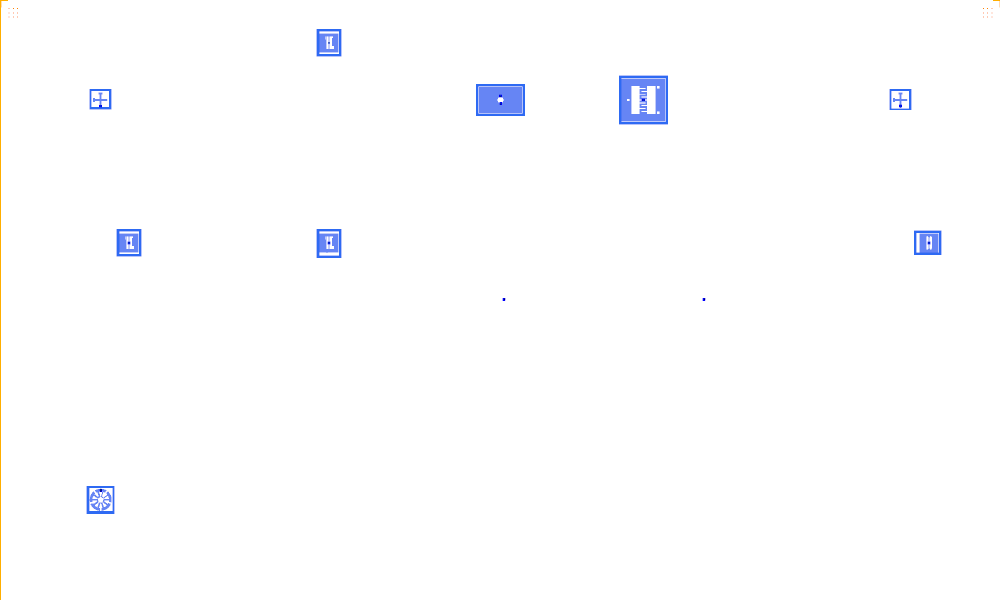

**On the chip so far:** 0 pads · 9 qubits · 2 other components · 0 routes · 0 declared couplings. **This step added** 11 component(s) `A01_Q1`, `A02_Q1`, `A03_qubit1`, `A04_qubit1`, `A05_Q1`, `A06_Q1`, `A07_Q1`, `A08_JJ2` … (+3).

WindowsPath('examples/designs/metal/component_examples_s3_qubits.png')

In [8]:
# Quantcore trilayer junctions on the PDK rule (Nb Δ 1.4 meV): every qubit the PDK nominal junction (0.5 × 0.6 µm →
# R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF); flux-tunable cells a Quantcore SQUID (R_n 45 kΩ in parallel); the
# interdigitated transmon (C_Σ ≈ 216 fF without the junction, this design's LOM before the rebuild) is sized for
# 4.05 GHz to stay inside the PDK's 4–8 GHz band (nominal: ≈ 3.95 GHz)
SQUIDS = {"TransmonCrossFL", "TunableCoupler01"}
LJ_PDK = trilayer_junction("metal:TransmonPocket")[1]["Lj_nH"]
LJ_FOR = {"TransmonInterdigitated": size_junction(4.05, 215.9, c_includes_junction=False).lj_nH}


def pdk_junction(cls):
    """``d.add`` keywords for a qubit class: ``junction_type`` (+ sizing) and the drawn junction's ``junction``."""
    squid = cls in SQUIDS
    params, junction = trilayer_junction(f"metal:{cls}", lj_nH=LJ_FOR.get(cls, LJ_PDK if squid else None), squid=squid)
    return dict(junction=junction, **params)


QUBITS = {"TransmonCross", "TransmonCrossFL", "TransmonPocket", "TransmonPocket6", "TransmonPocketCL",
          "TransmonPocketTeeth", "TransmonConcentric", "TransmonInterdigitated", "StarQubit", "TunableCoupler01"}
H = {}                                           # tile → {Metal name: handle}


def fits(pts, r):  # every segment of Metal's polyline takes two qcc fillets of radius r (the router's rule)
    return all(math.dist(a, b) >= 2 * r - 1e-6 for a, b in zip(pts, pts[1:]))


def place_tiles(group):
    """Add the components of every tile of one example group ("A" … "E"), with PDK junctions and open free pins."""
    with d.batch():
        for tile, ex in EX.items():
            if tile[0] != group:
                continue
            cx, cy = CENTRE[tile]
            used = {(r["ends"][0], r["ends"][1]) for r in ex["routes"].values()} | \
                   {(r["ends"][2], r["ends"][3]) for r in ex["routes"].values()}
            H[tile] = {}
            for n, c in ex["comps"].items():
                kw = pdk_junction(c["cls"]) if c["cls"] in QUBITS else {}
                free = [p for p in c["pins"] if (n, p) not in used]
                if free and c["cls"] != "OpenToGround":   # Metal draws a pin with no route as an open end
                    kw["open_pins"] = ",".join(free)
                H[tile][n] = d.add(f"{tile}_{n}", f"metal:{c['cls']}", at=(cx + c["at"][0], cy + c["at"][1]), rot=c["rot"],
                                   **kw, **c["opts"])


def route_tiles(group):
    """Add the routes of every tile of one example group on Metal's corner points (the rules above)."""
    with d.batch():
        for tile, ex in EX.items():
            if tile[0] != group:
                continue
            cx, cy = CENTRE[tile]
            h = H[tile]
            for n, r in ex["routes"].items():
                q0, p0, q1, p1 = r["ends"]
                otg = "OpenToGround" in (ex["comps"][q0]["cls"], ex["comps"][q1]["cls"])
                meander = r["cls"] == "RouteMeander"
                nodes = [(cx + x, cy + y) for x, y in r["pts"][1:-1]] if meander else []
                if meander and not fits(r["pts"], r["fillet"]):
                    print(f"{tile}_{n}: a Metal segment is shorter than its {r['fillet']:.2f} µm fillet: qcc meander footprint")
                    nodes, extra = [], dict(meander=r["length"])
                elif meander and not otg:
                    extra = dict(meander=r["length"] + 0.05)
                else:
                    extra = {}
                d.route(f"{tile}_{n}", getattr(h[q0], p0), getattr(h[q1], p1), r=r["fillet"] or 1, a=10, b=6,
                        nodes=nodes, **extra)


place_tiles("A")
route_tiles("A")
print(len(d.data["instances"]), "components;", "junctions:",
      {k: v for k, v in pdk_junction("TransmonCrossFL").items()}, "| interdigitated L_J",
      round(LJ_FOR["TransmonInterdigitated"], 3), "nH")
group_view("A", OUT / "component_examples_s3_qubits.png")

## Design 4 · Group B: the resonator

B.11: a λ/2 meander between two `OpenToGround`s (a resonator on its own, 9000 µm). One of Metal's segments is shorter
than two of its fillets, so the qcc meander picks its own footprint at Metal's length (the cell prints it).

B11_meanderTest: a Metal segment is shorter than its 99.99 µm fillet: qcc meander footprint


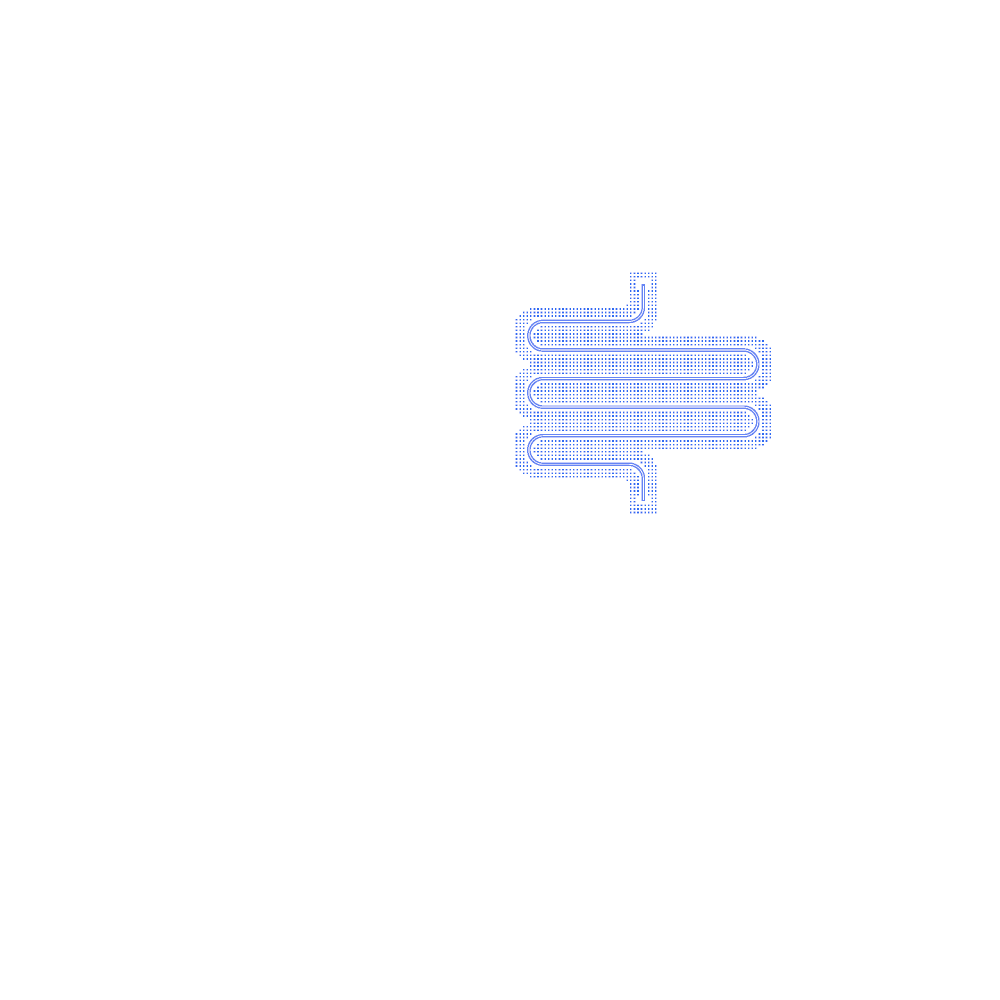

**On the chip so far:** 0 pads · 9 qubits · 4 other components · 1 routes · 0 declared couplings. **This step added** 2 component(s) `B11_Open_meander_start`, `B11_Open_meander_end` and 1 route(s) `B11_meanderTest`.

WindowsPath('examples/designs/metal/component_examples_s4_resonator.png')

In [9]:
place_tiles("B")
route_tiles("B")
group_view("B", OUT / "component_examples_s4_resonator.png")

## Design 5 · Group C: the composite

C.21: a `TransmonPocket` (PDK junction) with its 5 mm meander into an `OpenToGround`: a plain CPW on Metal's exact
path. It is the board's one qubit–resonator pair (the eigenmode job of Simulate 3).

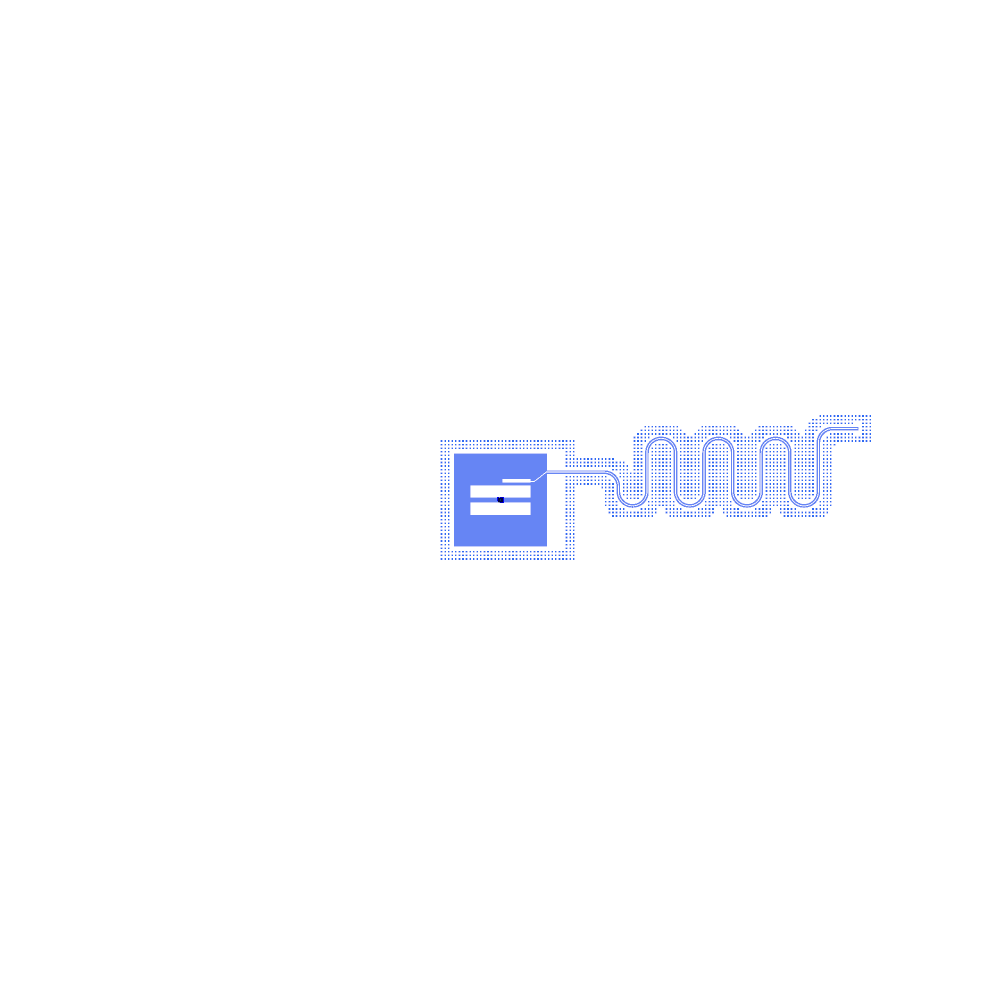

**On the chip so far:** 0 pads · 10 qubits · 5 other components · 2 routes · 0 declared couplings. **This step added** 2 component(s) `C21_Q1`, `C21_open_to_ground` and 1 route(s) `C21_coupler`.

WindowsPath('examples/designs/metal/component_examples_s5_composite.png')

In [10]:
place_tiles("C")
route_tiles("C")
group_view("C", OUT / "component_examples_s5_composite.png")

## Design 6 · Group D: the qubit couplers

D.31: two `TransmonCrossFL` crossmons with a `TunableCoupler01` between their arms (PDK SQUIDs on all three; no route
joins them: the coupling is geometric, the Q3D job `D31` measures it). D.32: two pockets joined by a 150 µm straight.
D.33: two pockets joined by a 5 mm λ/2 bus (a fixed-length meander on Metal's path). The second picture zooms on D.31
(the 95 µm bus claws inside the 200 µm arms).

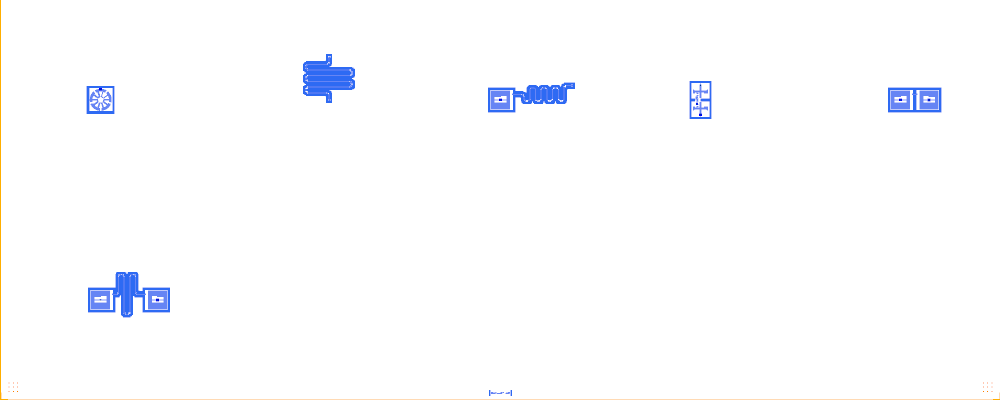

**On the chip so far:** 0 pads · 16 qubits · 6 other components · 4 routes · 0 declared couplings. **This step added** 7 component(s) `D31_Q1`, `D31_Q2`, `D31_Tune_C_Q12`, `D32_Q1`, `D32_Q2`, `D33_Q1`, `D33_Q2` and 2 route(s) `D32_coupler`, `D33_coupler`.

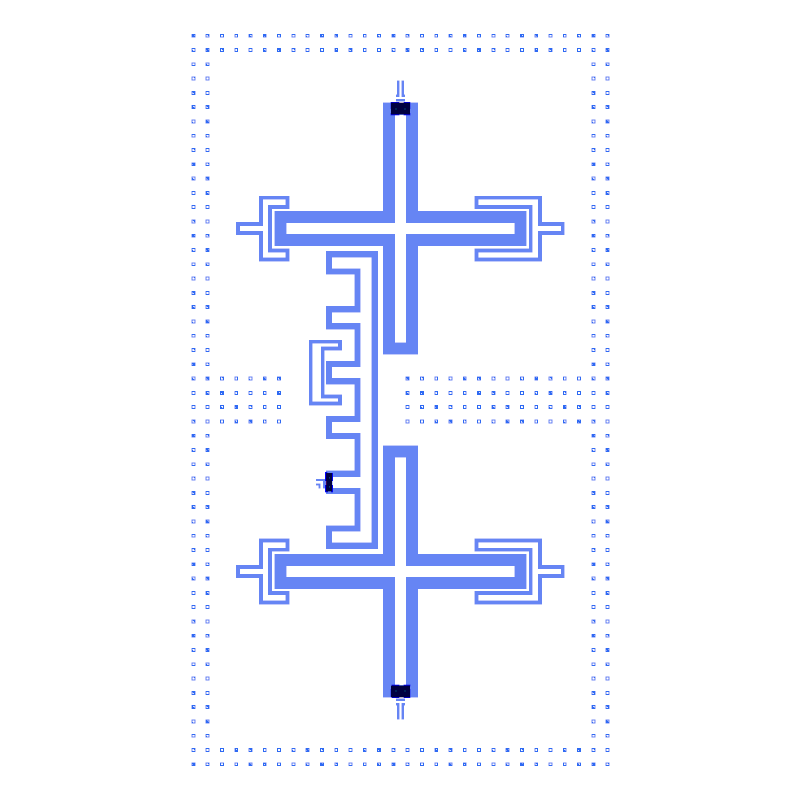

WindowsPath('examples/designs/metal/component_examples_step_parts.png')

In [11]:
place_tiles("D")
route_tiles("D")
group_view("D", OUT / "component_examples_s6_couplers.png")
cx, cy = CENTRE["D31"]
snap(d, OUT / "component_examples_step_parts.png", box=(cx - 700, cy - 700, cx + 700, cy + 700), size=(800, 800),
     width=320)

## Design 7 · Group E: input–output coupling

E.41: a `LaunchpadWirebondCoupled` on its own; E.42: a coupled launchpad driving a 10 mm open meander (its qcc
footprint at Metal's length, printed); E.43: a `TransmonPocketCL` with its charge-line pin. The two launchpads stay in
their tiles (Design 2).

E42_bus: a Metal segment is shorter than its 90.00 µm fillet: qcc meander footprint
26 components, 5 routes; not placed: none


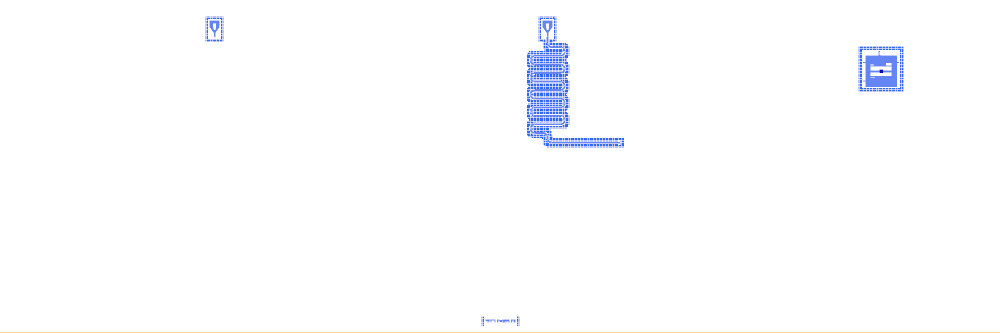

**On the chip so far:** 2 pads · 17 qubits · 7 other components · 5 routes · 0 declared couplings. **This step added** 4 component(s) `E41_P4_Q`, `E42_P4_Q`, `E42_open_to_ground`, `E43_Q1` and 1 route(s) `E42_bus`.

WindowsPath('examples/designs/metal/component_examples_s7_io.png')

In [12]:
place_tiles("E")
route_tiles("E")
missing = set(f"{t}_{n}" for t, ex in EX.items() for n in ex["comps"]) - set(d.data["instances"])
print(len(d.data["instances"]), "components,", len(d.data["routes"]), "routes; not placed:", missing or "none")
group_view("E", OUT / "component_examples_s7_io.png")

## Design 8 · The whole board: sim groups, centring, save

**Sim groups** (FEM boxes): A.01 (TransmonCross) and A.02 (TransmonPocket) alone, D.31 (two crossmons with the tunable
coupler; Q3D C-matrix each) and C.21 (a pocket qubit with its open meander; eigenmode).

**Centring.** The PDK wants the content centred in the die. The tiles are filled from the top left and the last row has only four
tiles (and the examples are not centred on their Metal origins), so the content leans up and right. `center_in_die`
shifts every component and route waypoint so the content's centre is the board's centre; the tile centres move with
it (`CENTRE`, used by the snapshots).

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's): the segments changed how the board is built, not the board, so it should say *same design* (here the
groups are placed in the source's order, so even the key order is the one-cell build's).

{'B11_meanderTest': 9000.0, 'C21_coupler': 5000.0, 'D32_coupler': 150.0, 'D33_coupler': 5000.0, 'E42_bus': 10000.0} (Metal: {'B11_meanderTest': 9000, 'C21_coupler': 5000, 'D32_coupler': 150, 'D33_coupler': 5000, 'E42_bus': 10000} )


content shifted by (-478.5, -935.6) µm


**Same design as before:** `examples/designs/metal/component_examples.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer component_examples: 26 instances, 5 routes, live=False> → examples\designs\metal\component_examples.json


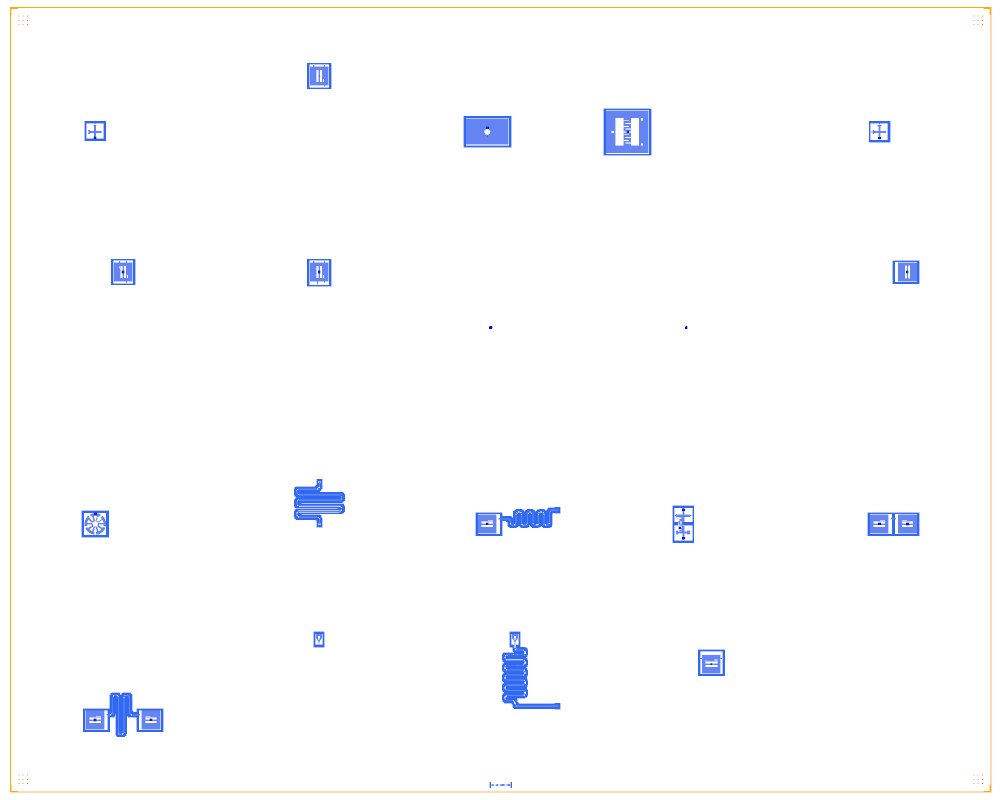

**On the chip so far:** 2 pads · 17 qubits · 7 other components · 5 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/component_examples_step_routes.png')

In [13]:
# FEM: a few tiles (qubit alone, coupler pair, qubit + meander)
d.sim_group("A01", ["A01_Q1"], margin_um=200, analyses=["q3d_cmatrix"])
d.sim_group("A02", ["A02_Q1"], margin_um=200, analyses=["q3d_cmatrix"])
d.sim_group("D31", ["D31_Q1", "D31_Q2", "D31_Tune_C_Q12"], margin_um=100, analyses=["q3d_cmatrix"])
d.sim_group("C21", ["C21_Q1", "C21_coupler", "C21_open_to_ground"], margin_um=200, analyses=["eigenmode_epr"])
rebuild(d)
L = d.result.route_lengths()
print({k: round(v, 1) for k, v in L.items()}, "(Metal:", {f"{t}_{n}": round(r["length"]) for t, e in EX.items()
                                                          for n, r in e["routes"].items()}, ")")
shift = center_in_die(d)
rebuild(d)
print("content shifted by", shift, "µm")
CENTRE = {t: (x + shift[0], y + shift[1]) for t, (x, y) in CENTRE.items()}
DESIGN, same = save_design(d, OUT / "component_examples.json")
display(Markdown(same))
print(d, "→", DESIGN)
layout_step(d, OUT / "component_examples_step_routes.png", size=(1000, 800), width=400)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here (from the v1 run): **no errors**. The `dangling_port` warnings are every pin the examples leave free (drawn open,
`open_pins`, as Metal draws a pin with no route) and the junction attachment points `squid_a` / `squid_b`. The two
`overlap` warnings are D.31's coupler bounding box over both crossmons, as in the source (it sits between their arms;
the metal does not touch). **PDK design warnings:** two `pad_edge` (the E.41 / E.42 launchpads, kept in their tiles:
Design 2). No `pdk_rn`: the nominal junctions are 45 kΩ, each PDK SQUID (A.05, D.31's two crossmons and coupler; two
90 kΩ junctions) is 45 kΩ in parallel, and the interdigitated transmon's sized junction is ≈ 43 kΩ. No `pdk_claw`:
every claw is inside its arm's reach. The A.08 / A.09 tiles are listed as junction type `Metal` (Metal's own
drawing, kept as a reference).

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [ ]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

Every `metal:` cell goes through its LOM model (the per-component table is `lom/metal_models.py`); routes between two
capacitive ends or between a pad and an `OpenToGround` are λ/2 `TLres`. The whole board (71 nodes) is one netlist;
the tiles are independent sub-circuits of it.

In [ ]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith(("A01_Q1.", "C21_"))})

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation, per tile

Each tile on its own (D.31's three cells one by one: the crossmon ↔ coupler couplings are geometric only, no route or
declared coupling carries them; its Q3D job gives them). These are per-cell checks of the LOM models with the PDK
junctions, not designs: the examples state no targets. Expected (estimates from the pre-rebuild LOM): crosses ≈ 5.8
GHz, pockets ≈ 7.1–7.4 GHz, Teeth ≈ 7.7 GHz, concentric ≈ 5.5 GHz, star ≈ 5.2 GHz, interdigitated 4.05 GHz, the D.31
coupler ≈ 8.6 GHz at zero flux (above the band, flagged in the summary). D.32 / D.33: two identical pockets hybridise
through the direct line / the λ/2 bus: ZZ not defined.

In [ ]:
groups = {t: [f"{t}_{n}" for n in [*e["comps"], *e["routes"]]] for t, e in EX.items()
          if t != "D31" and (any(c["cls"] in QUBITS for c in e["comps"].values()) or e["routes"])}
groups |= {f"D31_{n}": [f"D31_{n}"] for n in EX["D31"]["comps"]}   # no route or declared coupling joins them
res = {}
for t, sel in groups.items():
    try:
        res.update(simulate_groups(d, {t: sel}, max_modes=3))
    except Exception as e:                       # report, do not hide
        print(f"{t}: simulation failed: {type(e).__name__}: {str(e)[:120]}")
display(Markdown(groups_md(res)))
display(Markdown("**Static ZZ (QuTiP), coupled tiles:**\n\n" + zz_md({t: r for t, r in res.items() if t in ("D32", "D33")})))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) every normal mode of each tile (QuCat; circles are qubits, squares resonators;
filled markers are the QuTiP dressed values), (b) the dispersive shift |χ| of each resonator with a qubit (C.21, D.33).
From the v1 run the qubit classes spread over 4.07–7.76 GHz (the interdigitated transmon lowest, the Teeth pocket
highest) and the D.31 coupler sits at 8.57 GHz at zero flux.

In [ ]:
plot_lom(res, OUT / "component_examples_lom.png", title="component examples: LOM per tile")

## LOM 3 · One geometry change, by hand

Before the FEM, a hand-made design step. Copy the saved design (`design_copy`: a non-live Designer that never writes over the JSON), change one property —
here A.01's `TransmonCross` arm length `cross_length`, Metal's default 200 µm → 250 µm, the knob the PDK's `pdk_claw`
fix turns — and re-run tile A.01. Longer arms mean a larger C_Σ: f_q and |α| go down.

In [ ]:
d2 = design_copy(DESIGN)
d2["A01_Q1"].set(cross_length=250)               # 200 µm (Metal default) → 250 µm
res2 = simulate_groups(d2, {"A01": groups["A01"]}, max_modes=3)
display(Markdown(params_delta_md({"A01": res["A01"]}, res2)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/metal/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

Q3D C-matrix jobs for A.01 (TransmonCross) and A.02 (TransmonPocket) alone and for D.31 (two crossmons with
the tunable coupler), and an eigenmode job for C.21 (a TransmonPocket with its 5 mm open meander).

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/metal/fem/: solved results are kept here
jobs = export_sims(DESIGN, ["A01", "A02", "D31"])
jobs_eig = export_sims(DESIGN, ["C21"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrices

The capacitance of three tiles: `A01` (the `TransmonCross` alone: island and claws), `A02` (the floating
`TransmonPocket` alone: its two pads) and `D31` (the two crossmons and the tunable coupler: the islands and the
geometric couplings between them, which no route or declared coupling carries in the LOM). Each net is named after its
LOM node, so the matrix goes straight into the circuit (Results 3). `fem_stage` solves each job with `RUN_FEM`, else
loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The `C21` box in HFSS eigenmode: the pocket qubit's junction is a lumped L_J ‖ C_J sheet and its 5 mm meander ends open
at the `OpenToGround`, so the qubit and the λ/2 are the box's two lowest circuit modes. pyEPR (run inside qcc's own
AEDT, never KQC's `run_pyepr_t1_estimate.py`) turns the junction's energy participation into the dressed frequencies,
α and χ, to compare with the LOM.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run

Not exported for this board: C.21's meander ends open (no port to drive), and the tiles with launchpads (E.41 / E.42)
have no sim group (none is added: the board's JSON stays the source's).

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the qubit; ≈ 0: the meander), with the LOM's C.21 frequencies as
dashed lines. The table below lists the modes and the pyEPR values.

In [ ]:
lom_f = {"C21_Q1": res["C21"].params.get("C21_Q1.f_q_GHz"), "C21_coupler": res["C21"].params.get("C21_coupler.f_GHz")}
plot_eigenmodes(keep_eig, OUT / "component_examples_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode job in the LOM's terms: the qubit's mode is the one its junction participates in most, the meander's
the remaining mode nearest the LOM's f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr terms (κ ≈ 0:
nothing is terminated).

In [ ]:
fem_c21 = {}
if keep_eig.get("C21"):
    fem_c21 = epr_values(keep_eig["C21"], {"C21_Q1": "C21_coupler"}, {"C21_coupler": lom_f["C21_coupler"]})
if fem_c21:
    display(Markdown("| quantity | FEM |\n|---|---|\n" + "\n".join(
        f"| `{k}` | {v:.5g} |" for k, v in fem_c21.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q, α, f_r and χ of C.21 from pyEPR.")

## Results 3 · FEM against the LOM

**LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of A.01, A.02 and each D.31 cell (LOM 1's
groups) by their job's C-matrix values (matched by net name) and the same LOM runs again: f_q and α. (The D.31 cells
stay separate circuits: `fill` fills the branches the LOM has, and no branch joins the three islands.) **FEM
directly:** C.21's eigenmode values (Results 2). The left column is the LOM on the component estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill

JOB = {"A01": "A01", "A02": "A02", "D31_Q1": "D31", "D31_Q2": "D31", "D31_Tune_C_Q12": "D31"}   # LOM 1 group → its job
rows = []
for g, job in JOB.items():
    if keep_q3d.get(job) and g in res:
        on_fem = simulate(fill(d.lom(select=groups[g]).model, DESIGN, keep_q3d[job]), max_modes=3).params
        rows += [(f"{g}: {k}", v, on_fem.get(k), f"LOM on the {job} C-matrix") for k, v in res[g].params.items()
                 if k.endswith(("f_q_GHz", "alpha_MHz"))]
rows += [(k, res["C21"].params.get(k), v, "C21 eigenmode + pyEPR") for k, v in fem_c21.items() if k in res["C21"].params]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q and α of the LOM next to the LOM on each tile's "
          "Q3D C-matrix and next to C.21's eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards a target

The examples state no targets: they are component tests. This notebook sets one as an exercise on one tile: **A.01's
`TransmonCross` at 5.60 GHz** (dressed; from the v1 run 5.818 GHz, α −201 MHz). It is reachable inside the PDK junction
window: by the transmon formula (E_C ≈ |α| ≈ 0.2 GHz) its L_J goes from 6.73 nH to ≈ 7.25 nH, R_n ≈ 48.5 kΩ.

`loop.feedback` tunes qubit–readout pairs, and A.01 is a qubit alone. So the step is a first-order rule in the
notebook: f_q ∝ L_J^−1/2, so **L_J ← L_J · (f_now / f_target)²** (`rule_step`, exponent −0.5), kept inside the PDK
window (`pdk_lj_bounds`: R_n 40–50 kΩ). The new L_J is drawn (`trilayer_junction(..., lj_nH=...)` sizes the fingers
and gives C_J) on a copy of the board (`design_copy`), and tile A.01 is measured again (its LOM 1 group). Only L_J moves,
so the capacitances do not: when the `A01` Q3D job is kept (Simulate 2) its C-matrix fills every revision (the FEM
point), otherwise the LOM estimates do.

In [ ]:
from quantcore_circuits.assembly.drc import check

Q_T, F_T, TOL = "A01_Q1", 5.60, 0.020            # the exercise target: A.01 at 5.60 GHz ± 20 MHz (dressed)
LO, HI = pdk_lj_bounds(DESIGN)[f"{Q_T}.junction.Lj_nH"]   # the PDK R_n window as L_J bounds (nH)
FEM0 = keep_q3d.get("A01")                        # a kept Q3D job: its C-matrix holds for every revision


def f_a01_of(lj, it):
    """Revision it: A.01's junction drawn for lj nH on a copy, saved; its dressed f_q (LOM, on the kept C-matrix)."""
    d_k = design_copy(DESIGN, f"_rev{it}")
    jp, jj = trilayer_junction("metal:TransmonCross", lj_nH=lj)
    d_k[Q_T].set(junction=jj, **jp)
    path = d_k.save(Path("build") / "component_examples_target" / f"rev{it}.json")
    return simulate(fill(d_k.lom(select=groups["A01"]).model, d_k.design, FEM0), max_modes=3).params.get(
        f"{Q_T}.f_q_GHz"), path


LJ0 = d.data["instances"][Q_T]["junction"]["Lj_nH"]
F0 = simulate(fill(d.lom(select=groups["A01"]).model, DESIGN, FEM0), max_modes=3).params.get(f"{Q_T}.f_q_GHz")
LJ1 = min(max(rule_step(LJ0, F0, F_T, -0.5), LO), HI)
F1, REV1 = f_a01_of(LJ1, 1)
display(Markdown(before_after_md({"A01 L_J (nH)": LJ0, "A01 f_q (GHz)": F0}, {"A01 L_J (nH)": LJ1, "A01 f_q (GHz)": F1})))
print(f"target {F_T} ± {TOL} GHz; one step leaves {1e3 * (F1 - F_T):+.1f} MHz · revision 1: {REV1} · DRC:",
      "clean" if check(str(REV1)).ok else "ERRORS")

## Results 5 · Iterate to the target

The rule repeated (`rule_iterate`): revision k gets the new L_J, its LOM runs, and the next step uses the exponent of
the last two points (a secant in log–log), inside the PDK window, until A.01 is within 20 MHz or `MAX_ITER` steps are
made. The table shows each iteration (on: FEM when the C-matrix filled it, else LOM), the plot the residual in
tolerances (on target below 1).

In [ ]:
history = rule_iterate(f_a01_of, f"{Q_T}.f_q_GHz", f"{Q_T}.junction.Lj_nH", LJ0, F_T, TOL, -0.5, max_iter=MAX_ITER,
                       start=(F0, DESIGN), fem=FEM0 is not None, bounds=(LO, HI))
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "component_examples_iterate.png")
last = history[-1]["design"]
print("last design:", last, "· DRC:", "clean" if check(str(last)).ok else "ERRORS", "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

The design JSON saved in Design 8 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese.** None of the A–E example notebooks exports a GDS, so the originals have no cheese: the PDK band
applies (`cheese: "auto"`, the default). The build draws it into KQC's `ground_grid` layer (5 µm squares, 20 µm gaps,
three rows round the 3/0 keep-outs) and `export_fab` keeps it (`cheese source: build`). The A.08 / A.09 junction
tiles keep Metal's single-layer junction drawing (2/0), so they add 2/0 polygons without 4/0.

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [ ]:
print("design file:", DESIGN)
CHEESE = True
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

## Fab 2 · Snapshots

The whole board (tiles left to right, top to bottom: A01 … A11, B11, C21, D31 … D33, E41 … E43); then tiles D31 (two
crossmons and the tunable coupler, compare the source's screenshot; the 95 µm bus claws inside the 200 µm arms),
C21 (pocket qubit and its open meander) and E42 (the coupled launchpad to an open 10 mm meander), the A.08 Dolan
junction, the **fab mask** of tile D31 (1/0 etch with the PDK cheese band, the 3/0 keep-outs, the junction layers),
and the die frame's south-west corner (dicing L on 1000/0, alignment grid on 1001/0). The tile centres include the
centring shift.

In [ ]:
def tile_box(t, half=3500):
    cx, cy = CENTRE[t]
    return (cx - half, cy - half, cx + half, cy + half)


show_snapshot(d, OUT / "component_examples.png", size=(1500, 1200))
show_snapshot(d, OUT / "component_examples_d31.png", box=tile_box("D31", 700), size=(1000, 1000), width=480)
show_snapshot(d, OUT / "component_examples_c21.png", box=tile_box("C21", 3000), size=(1000, 1000), width=480)
show_snapshot(d, OUT / "component_examples_e42.png", box=tile_box("E42", 3500), size=(1000, 1000), width=480)
cx, cy = CENTRE["A08"]
show_snapshot(d, OUT / "component_examples_jj.png", box=(cx + 60, cy - 40, cx + 140, cy + 40), size=(800, 800), width=320)
snap_file(Path("build") / "component_examples_fab.oas", OUT / "component_examples_cheese.png",
          box=tile_box("D31", 700), size=(1000, 1000), width=480)
show_snapshot(d, OUT / "component_examples_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300);

## Summary

| | |
|---|---|
| matches the source | every example's components with the options its notebook set, positions and orientations, every route's end pins, Metal corner points and length (B.11 / E.42 meanders at Metal's length on a qcc footprint), the sim groups |
| PDK changes | QCT frame on the 35 × 28 mm board; sapphire stack; trilayer junctions (nominal, SQUIDs, the interdigitated transmon sized for 4.05 GHz); PDK cheese band; the tile grid centred in the die (shift (−478, −936) µm in the v1 run) |
| differs | a catalogue board, not a chip: the E.41 / E.42 launchpads stay in their tiles; the A.08 / A.09 junction tiles keep Metal's drawing; the analysis cells of the examples are not reproduced |
| PDK design warnings | `pad_edge` × 2 (E.41 / E.42, by choice, Design 2) |
| layout | built one example group at a time (the board, A qubits, B resonator, C composite, D couplers, E input–output, the whole board), in the source's order; the saved JSON is the v1 notebook's |
| feedback | an exercise target on one tile (A.01 5.60 GHz) by a first-order L_J rule on board copies (no qubit–readout pair for `loop.feedback`); LOM, or the A01 Q3D capacitances when the job is kept |
| open | the D.31 coupler sits above 8 GHz at zero flux; D.32 / D.33 hybridise (identical pockets); the FEM jobs (Q3D, C.21 eigenmode) are exported, not solved (`RUN_FEM = False`) |